# 03 GELO APOIADO: MÁSCARA FÍSICA, AJUSTE ESPAÇO-TEMPORAL (`FITSEC`), TENDÊNCIAS, ACELERAÇÃO, ALIASING E INTERPOLAÇÃO

Este caderno detalha toda a cadeia de estimação da taxa de mudança de elevação ($\text{dh/dt}$) sobre o gelo continental apoiado (*grounded ice*) da bacia do Mar de Amundsen:
1. **Máscara de gelo apoiado (`BedMachine Antarctica v4.1`, Morlighem et al., 2020) e filtro posicional de nós (`dhdt_nodes_qc`):** por que filtrar apenas os pontos de entrada é insuficiente quando o raio de busca nodal é de $15\text{ km}$, e como a remoção dos $1.464$ nós posicionados fora do gelo apoiado corrige a assimetria (*skewness*) da distribuição de $-2{,}47$ para $-2{,}01$;
2. **Rota independente livre de modelo (`run_perfil_bruto.py`):** verificação do rebaixamento da Thwaites usando exclusivamente medianas em painel balanceado de células fixas de $2\text{ km}$ ($-16{,}30\text{ m}$ em JJA, diferindo em apenas $+0{,}04\text{ m}$ do modelo `fitsec`);
3. **Seleção multi-critério de aceleração (`thwaites.timeseries.acceleration`):** por que $99{,}6\%$ dos nós são rejeitados por autocorrelação residual ($r_1 \in [0{,}52;\; 0{,}70]$);
4. **Decomposição física do viés sazonal da janela de inverno (JJA vs. ciclo anual):** separação entre aliasing harmônico estacionário ($\le 2\%$, método do ATBD ATL14/15 §5), componente de firn/SMB no GSFC-FDM e sinal total no produto externo ATL15 ($r = 0{,}964$);
5. **Seleção objetiva do interpolador espacial por *Spatial Block Cross-Validation* (`thwaites.interp.select`).**

### Roteiro do caderno
| Seção | Fundamentação | Aplicação em código | Módulo |
|---|---|---|---|
| 0 | Máscara de gelo apoiado e populações de nós | tabela de diagnósticos nodais do produto real | `thwaites.qc.grounded_mask`, `thwaites.qc.reliability` |
| 1 | Ajuste espaço-temporal local `fitsec` | nó sintético com topografia inclinada, amostragem irregular e blunders | `thwaites.timeseries.dhdt` |
| 2 | Seleção de aceleração por múltiplos critérios | aceleração verdadeira vs. anomalia interanual AR(1) | `thwaites.timeseries.acceleration` |
| 3 | Viés sazonal da janela JJA | vazamento de harmônicos com amostragem JJA vs. ano inteiro + resultados reais | `thwaites.timeseries.aliasing` |
| 4 | Seleção do interpolador por CV espacial em blocos | métricas reais JJA × DJF | `thwaites.interp.select` |
| 5 | Síntese | — | — |

In [1]:
# ── Configuração comum do caderno ─────────────────────────────────────────────
# Localiza a raiz do repositório (a pasta que contém o pacote `thwaites/`), torna o
# pacote importável mesmo sem `pip install -e .` e aponta DATA_DIR para as tabelas
# resumidas que alimentam todas as figuras. Basta executar o caderno de cima para baixo.
import sys
import json
from pathlib import Path

_candidatas = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in _candidatas if (p / "thwaites").is_dir()), None)
if REPO_ROOT is None:
    raise RuntimeError("Execute o caderno a partir de dentro do repositório (pasta com 'thwaites/').")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
DATA_DIR = REPO_ROOT / "notebooks" / "dados_resumo"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 9, "axes.titlesize": 9.5,
})
# Mensagens de log da biblioteca: só erros (os cadernos não chamam setup_logging()).
try:
    from loguru import logger as _logger
    import thwaites.logging as _tlog
    _logger.remove()
    _logger.add(sys.stderr, level="ERROR", format="{level}: {message}")
    _tlog._CONFIGURED = True
except ImportError:
    pass

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
CORES = {"Pine_Island": "#0F4D92", "Thwaites_TEIS": "#B64342", "Crosson": "#42949E",
         "Dotson": "#9A4D8E", "Cosgrove": "#767676"}
print(f"Tabelas resumidas disponíveis em dados_resumo/: {len(list(DATA_DIR.glob('*')))}")

Tabelas resumidas disponíveis em dados_resumo/: 74


---
## 0. Populações de Nós e Verificações Independentes do Produto
A tabela abaixo resume, a partir dos relatórios do pipeline, o que acontece com os nós de dh/dt desde o ajuste bruto até o produto validado.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

qc_nodes = json.loads((DATA_DIR / "jja_qc_report.json").read_text(encoding="utf-8"))
rel_crit = json.loads((DATA_DIR / "jja_reliability_criteria.json").read_text(encoding="utf-8"))
accel_rep = json.loads((DATA_DIR / "jja_accel_summary.json").read_text(encoding="utf-8"))
alias_rep = json.loads((DATA_DIR / "jja_aliasing_report.json").read_text(encoding="utf-8"))
bruto_rep = json.loads((DATA_DIR / "comparacao_sazonal_perfil_bruto.json").read_text(encoding="utf-8"))
xover_jja = json.loads((DATA_DIR / "jja_xover_summary.json").read_text(encoding="utf-8"))

# Comparação entre o conjunto cru de nós (antes do filtro posicional) e o produto validado dhdt_nodes_qc
pd.DataFrame([
    {"População / Diagnóstico Nodal (JJA 2019–2025)": "Nós ajustados totais antes do filtro posicional (dhdt_nodes.parquet)", "Contagem / Valor": "8.695 nós (inclui 771 sobre oceano e 1.128 sobre plataforma que capturavam terra no raio de 15 km)"},
    {"População / Diagnóstico Nodal (JJA 2019–2025)": "Nós validados no domínio apoiado + buffers (dhdt_nodes_qc.parquet)", "Contagem / Valor": "7.231 nós (mask==2, dist_GL ≥ 5 km, dist_costa ≥ 2 km, fração apoiada no raio ≥ 50%)"},
    {"População / Diagnóstico Nodal (JJA 2019–2025)": "Mudança nas estatísticas após filtro posicional (Cru → Validado)", "Contagem / Valor": "Mediana: −0,288 → −0,308 m/ano | Média: −0,616 → −0,593 m/ano | Skewness: −2,47 → −2,01"},
    {"População / Diagnóstico Nodal (JJA 2019–2025)": "Classificação de confiabilidade nodal (thwaites.qc.reliability)", "Contagem / Valor": "4.585 confiáveis (63,4%) | 2.607 aceitáveis (36,1%) | 39 não confiáveis (0,5%)"},
    {"População / Diagnóstico Nodal (JJA 2019–2025)": "Aceleração quadrática sustentada nos 6 critérios (run_acceleration.py)", "Contagem / Valor": f"{accel_rep['n_accel_supported']} de {accel_rep['n_nodes']:,} nós ({100*accel_rep['frac_supported']:.2f}%) — 99,6% rejeitados por resíduo autocorrelacionado (ac1 = 0,52–0,70)"},
    {"População / Diagnóstico Nodal (JJA 2019–2025)": "Consistência interna contra 7.023 cruzamentos orbitais (xovers)", "Contagem / Valor": f"Mediana xover = {xover_jja['xover_dhdt_median']:+.3f} vs fitsec = {xover_jja['fitsec_dhdt_median']:+.3f} m/ano (dif = {xover_jja['difference_median']:+.3f} m/ano)"},
    {"População / Diagnóstico Nodal (JJA 2019–2025)": "Verificação livre de modelo por medianas em painel balanceado (2 km)", "Contagem / Valor": f"Rebaixamento 2019→2025 a jusante: JJA = {bruto_rep['estacoes']['JJA']['rebaixamento_jusante_m']:+.2f} m | DJF = {bruto_rep['estacoes']['DJF']['rebaixamento_jusante_m']:+.2f} m (dif. contra fitsec: +0,04 m)"},
]).set_index("População / Diagnóstico Nodal (JJA 2019–2025)")

,Contagem / Valor
População / Diagnóstico Nodal (JJA 2019–2025),
Nós ajustados totais antes do filtro posicional (dhdt_nodes.parquet),8.695 nós (inclui 771 sobre oceano e 1.128 sob...
Nós validados no domínio apoiado + buffers (dhdt_nodes_qc.parquet),"7.231 nós (mask==2, dist_GL ≥ 5 km, dist_costa..."
Mudança nas estatísticas após filtro posicional (Cru → Validado),"Mediana: −0,288 → −0,308 m/ano | Média: −0,616..."
Classificação de confiabilidade nodal (thwaites.qc.reliability),"4.585 confiáveis (63,4%) | 2.607 aceitáveis (3..."
Aceleração quadrática sustentada nos 6 critérios (run_acceleration.py),"31 de 7,231 nós (0.43%) — 99,6% rejeitados por..."
Consistência interna contra 7.023 cruzamentos orbitais (xovers),Mediana xover = -0.320 vs fitsec = -0.268 m/an...
Verificação livre de modelo por medianas em painel balanceado (2 km),Rebaixamento 2019→2025 a jusante: JJA = -16.30...


**Leitura da tabela.**
- **Filtro posicional:** 1.464 nós (17%) estavam centrados sobre oceano ou plataforma e "capturavam" segmentos de gelo apoiado dentro do raio de 15 km. Removê-los muda pouco a mediana, mas reduz a cauda negativa (skewness de $-2{,}47$ para $-2{,}01$). Filtrar apenas os *pontos* de entrada não basta: o que importa é onde o **nó** está.
- **Confiabilidade:** 63% dos nós cumprem os critérios estritos (≥ 5.000 observações, ≥ 5 anos, $\sigma \le 0{,}15$ m/ano) e só 0,5% são não confiáveis.
- **Aceleração:** apenas 31 nós (0,43%) sustentam um termo quadrático (Seção 2).
- **Verificações independentes:** os cruzamentos orbitais (sem modelo espacial) e a rota de medianas em painel balanceado (sem nenhum ajuste) concordam com o `fitsec` em poucos centímetros por ano e em $+0{,}04\text{ m}$ no rebaixamento acumulado da Thwaites. O resultado, portanto, não é um artefato do estimador.

---
## 1. O Ajuste `fitsec` num Nó: Por Que os Termos Espaciais São Indispensáveis

**Fundamentação.** Em cada nó (raio de 15 km), as elevações são modeladas como superfície quadrática local mais tendência temporal:
$$h(x, y, t) = p_0 + \underbrace{p_x\,\Delta x + p_y\,\Delta y + p_{xy}\,\Delta x\Delta y + p_{xx}\,\Delta x^2 + p_{yy}\,\Delta y^2}_{\text{topografia local}} + \underbrace{\dot h\,(t - t_{\text{ref}})}_{\text{dh/dt}} + \tfrac{1}{2}\ddot h\,(t - t_{\text{ref}})^2 + \varepsilon$$
ajustada por mínimos quadrados ponderados com rejeição iterativa de resíduos acima de $3\,\hat\sigma_{\text{MAD}}$. As trilhas do ICESat-2 não passam exatamente pelos mesmos pontos a cada ano. Se a topografia não for modelada, a mudança de *onde* se mediu aparece como mudança de *quanto* se mediu.

**Aplicação.** Nó sintético com encosta de 1,2% (12 m/km), 3 trilhas por inverno em posições sorteadas, 2% de blunders e dh/dt verdadeiro de $-0{,}80\text{ m/ano}$. Usamos o estimador de produção (`_fit_node`, o mesmo chamado por `compute_tile_dhdt`) com a configuração `jja`:

,dh/dt (m/ano),Erro vs. verdade (m/ano),σ formal (m/ano),RMSE do ajuste (m),Obs. retidas
Estimador,,,,,
fitsec de produção (quadrática + rejeição MAD),-0.8047,-0.0047,0.0023,0.2900,5298.0
fitsec sem rejeição robusta (max_iter = 1),-0.8157,-0.0157,0.0224,2.8600,5307.0
fitsec sem termos espaciais (poly_order = 0),-9.3172,-8.5172,0.1122,2.7725,118.0
Regressão simples h ~ t (sem modelo),-9.6275,-8.8275,NaN,NaN,NaN


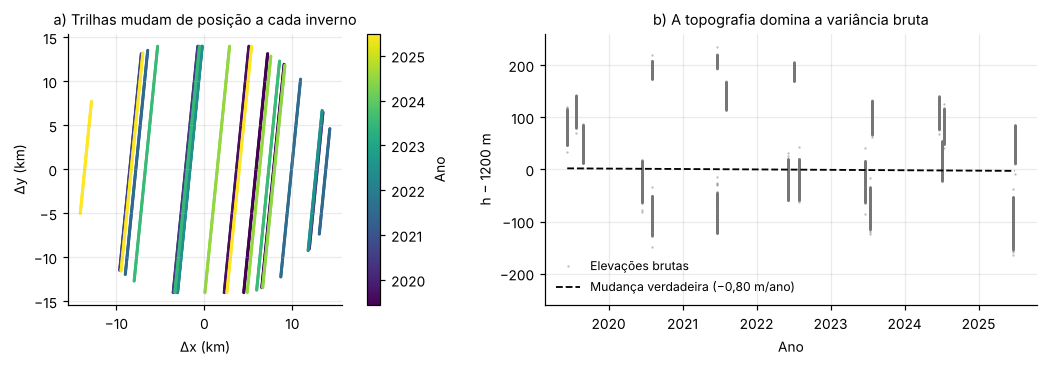

In [3]:
from thwaites import load_config
from thwaites.timeseries.dhdt import _fit_node

cfg = load_config("jja")
d = cfg.dhdt
rng = np.random.default_rng(21)
xs, ys, ts = [], [], []
for ano in range(2019, 2026):
    for _ in range(3):                                         # 3 trilhas por inverno, posições sorteadas
        x0 = rng.uniform(-14e3, 14e3)
        yy = np.linspace(-14e3, 14e3, 300); xx = x0 + 0.1 * yy
        ok = xx**2 + yy**2 < d.search_radius_m**2
        xs.append(xx[ok]); ys.append(yy[ok]); ts.append(np.full(ok.sum(), ano + rng.uniform(0.42, 0.66)))
X, Y, T = map(np.concatenate, (xs, ys, ts))
topo = 1200 + 0.012 * X - 0.004 * Y + 2e-7 * X**2               # encosta + curvatura
h = topo - 0.80 * (T - 2022) + rng.normal(0, 0.30, T.size)
blunder = rng.random(T.size) < 0.02
h[blunder] += rng.choice([-1, 1], blunder.sum()) * rng.uniform(5, 30, blunder.sum())
sig = np.full(T.size, 0.05)

variantes = {
    "fitsec de produção (quadrática + rejeição MAD)": d,
    "fitsec sem rejeição robusta (max_iter = 1)": d.model_copy(update={"max_iter": 1}),
    "fitsec sem termos espaciais (poly_order = 0)": d.model_copy(update={"poly_order": 0}),
}
linhas = []
for nome, dd in variantes.items():
    r = _fit_node(X, Y, h, T, sig, 0.0, 0.0, dd)
    linhas.append({"Estimador": nome, "dh/dt (m/ano)": r["dhdt"], "Erro vs. verdade (m/ano)": r["dhdt"] + 0.80,
                   "σ formal (m/ano)": r["dhdt_err"], "RMSE do ajuste (m)": r["rmse"], "Obs. retidas": r["nobs"]})
linhas.append({"Estimador": "Regressão simples h ~ t (sem modelo)", "dh/dt (m/ano)": np.polyfit(T, h, 1)[0],
               "Erro vs. verdade (m/ano)": np.polyfit(T, h, 1)[0] + 0.80})

fig, ax = plt.subplots(1, 2, figsize=(10.4, 3.4))
sc = ax[0].scatter(X / 1e3, Y / 1e3, c=T, s=1, cmap="viridis")
plt.colorbar(sc, ax=ax[0], label="Ano")
ax[0].set_aspect("equal"); ax[0].set_xlabel("Δx (km)"); ax[0].set_ylabel("Δy (km)")
ax[0].set_title("a) Trilhas mudam de posição a cada inverno")
ax[1].plot(T, h - 1200, ".", ms=1, color="#767676", alpha=0.5, label="Elevações brutas")
ax[1].plot(np.sort(T), -0.80 * (np.sort(T) - 2022), "k--", lw=1.2, label="Mudança verdadeira (−0,80 m/ano)")
ax[1].set_ylim(-260, 260); ax[1].set_xlabel("Ano"); ax[1].set_ylabel("h − 1200 m")
ax[1].set_title("b) A topografia domina a variância bruta"); ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
pd.DataFrame(linhas).set_index("Estimador").round(4)

**Leitura do resultado.**
- O `fitsec` de produção recupera $-0{,}80\text{ m/ano}$ com erro de milímetros por ano.
- Sem termos espaciais, a estimativa erra por um fator > 10: a variância da elevação bruta (centenas de metros ao longo da encosta) é ordens de grandeza maior que o sinal temporal (metros). Nesse caso a rejeição MAD descarta quase todo o dado, porque tudo parece outlier.
- Sem a rejeição robusta, a taxa muda pouco *neste* exemplo, porque os blunders são simétricos. Mas o RMSE do ajuste e o $\sigma$ formal ficam ~10× inflados, e são eles que alimentam os pesos, a classificação de confiabilidade e o QC dos nós. Com erros unilaterais (nuvens sempre acima da superfície), a própria taxa também seria enviesada.
- O $\sigma$ formal impresso (~2 mm/ano) é otimista: ele trata os 5.000 segmentos como independentes. A incerteza publicada vem do jackknife por ano (Caderno 00 §2.4, Caderno 04 §2), tipicamente 10–100× maior.

---
## 2. Aceleração: Por Que 99,6% dos Nós São Rejeitados

**Fundamentação.** Com 7 invernos, uma anomalia interanual autocorrelacionada (por exemplo, a sequência de anos de acumulação alta em 2019–2021) produz uma curvatura que o termo $\frac{1}{2}\ddot h\,\Delta t^2$ captura com facilidade. `assess_acceleration` só aceita aceleração se **seis critérios independentes** concordarem: $\Delta\text{AIC}_c \ge 2$; ganho de predição retendo um ano inteiro; IC de bootstrap **por ano** sem cruzar zero; sinal estável em ≥ 95% das réplicas; nenhum ano isolado sustentando o resultado; e autocorrelação residual $|r_1| \le 0{,}5$.

**Aplicação.** Dois nós sintéticos com o mesmo número de dados: (A) aceleração verdadeira de $-0{,}25\text{ m/ano}^2$; (B) **sem aceleração**, mas com anomalias interanuais AR(1) ($\phi = 0{,}7$, $\sigma = 0{,}35$ m):

,ΔAICc (linear − quadrático),IC95% bootstrap por ano (m/ano²),Aceleração estimada (m/ano²),Sinal estável no bootstrap,|r1| resíduo,Aceleração aceita?,Motivo
Nó,,,,,,,
"A: aceleração verdadeira (−0,25 m/ano²)",2092.733,[-0.273; -0.142],-0.231,1.00,0.025,True,todos os critérios atendidos
B: sem aceleração + anomalia AR(1),707.053,[-0.645; 0.482],NaN,0.92,0.445,False,IC bootstrap (por ano) da aceleração cruza zer...


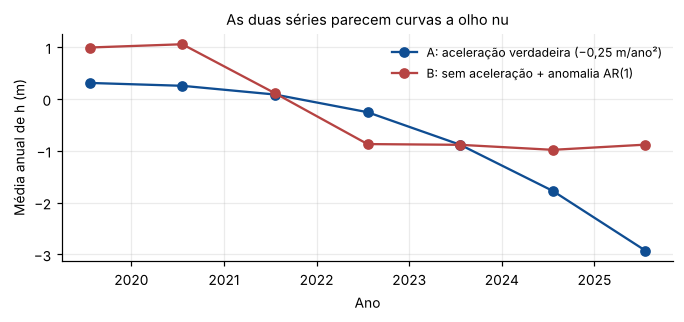

In [4]:
from thwaites.timeseries.acceleration import assess_acceleration

def no_sintetico(caso, seed=11):
    rng = np.random.default_rng(seed)
    anos = np.arange(2019, 2026)
    t = np.concatenate([a + 0.45 + rng.uniform(0, 0.2, 300) for a in anos])
    k = np.floor(t).astype(int) - anos[0]
    dx = rng.uniform(-15e3, 15e3, t.size); dy = rng.uniform(-15e3, 15e3, t.size)
    sinal = -0.40 * (t - 2022)
    if caso == "A":
        sinal = sinal + 0.5 * (-0.25) * (t - 2022) ** 2
        anomalia = rng.normal(0, 0.05, anos.size)
    else:
        anomalia = np.zeros(anos.size)
        for j in range(1, anos.size):
            anomalia[j] = 0.7 * anomalia[j - 1] + rng.normal(0, 0.35)
    h = sinal + anomalia[k] + 1e-4 * dx + rng.normal(0, 0.30, t.size)
    return t, h, dx, dy

fig, ax = plt.subplots(figsize=(6.4, 3.0))
linhas = []
for caso, rotulo, cor in [("A", "A: aceleração verdadeira (−0,25 m/ano²)", "#0F4D92"),
                          ("B", "B: sem aceleração + anomalia AR(1)", "#B64342")]:
    t, h, dx, dy = no_sintetico(caso)
    r = assess_acceleration(h, t, dx, dy, t_ref=2022.0, seed=1)
    medias = pd.Series(h - 1e-4 * dx).groupby(np.floor(t)).mean()
    ax.plot(medias.index + 0.55, medias.values, "o-", color=cor, label=rotulo)
    linhas.append({"Nó": rotulo, "ΔAICc (linear − quadrático)": r["delta_aicc"],
                   "IC95% bootstrap por ano (m/ano²)": f"[{r['accel_ci95_lo']:.3f}; {r['accel_ci95_hi']:.3f}]",
                   "Aceleração estimada (m/ano²)": r["accel"], "Sinal estável no bootstrap": r["boot_sign_frac"], "|r1| resíduo": r["resid_ac1"],
                   "Aceleração aceita?": r["accel_supported"], "Motivo": r["reason"]})
ax.set_xlabel("Ano"); ax.set_ylabel("Média anual de h (m)"); ax.legend(frameon=False, fontsize=8)
ax.set_title("As duas séries parecem curvas a olho nu"); plt.tight_layout()
pd.DataFrame(linhas).set_index("Nó").round(3)

**Leitura do resultado.**
- No nó **B** não existe aceleração, mas o $\Delta\text{AIC}_c$ é de centenas de unidades: o critério de informação, sozinho, "aprovaria" uma aceleração espúria, porque trata os 2.100 segmentos como independentes. O bootstrap que reamostra **anos inteiros** mostra que o IC cruza zero e rejeita o termo.
- No nó **A**, com aceleração verdadeira, todos os critérios passam e o valor recuperado é próximo de $-0{,}25\text{ m/ano}^2$. No nó B, o valor fica `NaN`: o pipeline não reporta uma aceleração que não se sustenta.
- No produto real, os nós rejeitados têm resíduos com $r_1 = 0{,}52$–$0{,}70$ (tabela abaixo): é exatamente o caso B. A conclusão científica é que **7 anos de ICESat-2 não bastam para afirmar aceleração** na maior parte da bacia, e o pipeline reporta a taxa linear com sua incerteza.

In [5]:
motivos = pd.Series(accel_rep["top_rejection_reasons"], name="Nós rejeitados por este motivo").to_frame()
print(f"Nós avaliados: {accel_rep['n_nodes']:,} | aceleração sustentada: {accel_rep['n_accel_supported']} "
      f"({100*accel_rep['frac_supported']:.2f}%) | mediana da aceleração aceita: {accel_rep['accel_median_supported']:+.3f} m/ano²")
motivos

Nós avaliados: 7,231 | aceleração sustentada: 31 (0.43%) | mediana da aceleração aceita: +0.454 m/ano²


,Nós rejeitados por este motivo
resíduo autocorrelacionado (ac1=0.52),127
resíduo autocorrelacionado (ac1=0.61),127
resíduo autocorrelacionado (ac1=0.65),123
resíduo autocorrelacionado (ac1=0.55),119
resíduo autocorrelacionado (ac1=0.68),119
resíduo autocorrelacionado (ac1=0.70),119


---
## 3. Decomposição do Viés Sazonal (Inverno JJA vs. Verão DJF vs. Ciclo Anual Completo)

Uma questão metodológica central na literatura de altimetria polar é se restringir a janela observacional ao inverno austral (JJA — para minimizar fusão superficial e mudanças na propriedade dielétrica/espalhamento da neve) introduz viés na tendência plurianual $\text{dh/dt}$. O projeto executou **três experimentos complementares** que decompõem esse efeito:
1. **Teste 1 — Aliasing Harmônico Estacionário (`thwaites.timeseries.aliasing`, método do ATBD ATL14/15 r005 §5):** Injetamos senoides sintéticas de frequência anual ($1\text{ ciclo/ano}$) e semianual ($2\text{ ciclos/ano}$) com amplitude unitária ($1\text{ m}$) exatamente nos timestamps orbitais reais $t_i$ de cada um dos $8.695$ nós e passamos pelo estimador de produção `fitsec`, maximizando sobre a fase $\phi \in [0, 2\pi)$. O fator de transferência mediano em JJA é $R_{\text{anual}} = 0{,}0551\text{ (m/ano)/m}$. Multiplicado pela amplitude sazonal mediana do firn no GSFC-FDM ($0{,}127\text{ m}$), o vazamento de aliasing estacionário é de apenas **$+0{,}007\text{ m/ano}$ ($\sim 2\%$ do sinal)**;
2. **Teste 2 — Amostragem Sazonal de Anomalias Interanuais de Firn/SMB (`GSFC-FDM v1.2.1`):** Comparando a tendência calculada apenas nas épocas JJA ($57$ épocas) contra todas as épocas do ano ($219$ épocas) no mesmo modelo de firn em 2019–2021 ($3.378$ células), a janela JJA captura menos do evento de acúmulo alto daquele triênio ($+0{,}113$ vs. $+0{,}146\text{ m/ano}$, diferença de $-0{,}027\text{ m/ano} \approx -4{,}2\text{ Gt/ano}$, sentido anti-conservador nesta componente isolada);
3. **Teste 3 — Sinal Total Observado no Produto Oficial ATL15 v005 e Comparação Pareada JJA $\times$ DJF:** No sinal glaciológico total do ATL15 (dinâmica + firn + SMB, 2019–2025), a taxa restrita aos trimestres de inverno é $-0{,}282\text{ m/ano}$ contra $-0{,}327\text{ m/ano}$ no ciclo anual completo (**razão JJA/anual $= 0{,}862$**, confirmando que no sinal líquido total a janela de inverno é **$\sim 14\%$ conservadora**). E nos $7.230$ nós comuns entre os nossos processamentos independentes de JJA e DJF, as taxas médias diferem em apenas $-0{,}033 \pm 0{,}005\text{ m/ano}$ ($\sim 5\%$).

**Aplicação do Teste 1.** `node_response` injeta harmônicos de 1 m de amplitude nas épocas observadas e mede quanto vaza para dh/dt, usando o mesmo estimador de produção. Comparamos uma amostragem só de inverno (frações de ano 0,42–0,66) com uma amostragem espalhada pelo ano inteiro, ambas com 8 passagens por ano:

Vazamento estacionário estimado em JJA: R_anual × amplitude FDM = 0.0551 × 0.127 m = +0.0070 m/ano


Nó sintético                  Produto real (mediana nos nós)            
           Ano inteiro Só inverno (JJA)               Só inverno (JJA) Ano inteiro
anual           0.0924           0.0135                         0.0551      0.1369
semianual       0.1575           0.0241                         0.1023      0.1228

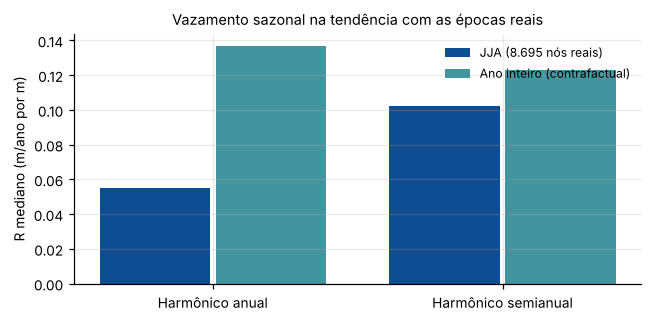

In [6]:
from thwaites.timeseries.aliasing import node_response

rng = np.random.default_rng(5)
anos = np.arange(2019, 2026)
amostragens = {
    "Só inverno (JJA)": np.concatenate([a + np.repeat(rng.uniform(0.42, 0.66, 8), 40) for a in anos]),
    "Ano inteiro": np.concatenate([a + np.repeat(rng.uniform(0.00, 1.00, 8), 40) for a in anos]),
}
linhas = []
for nome, tt in amostragens.items():
    x = rng.uniform(-15e3, 15e3, tt.size); y = rng.uniform(-15e3, 15e3, tt.size)
    for periodo, rot in [(1.0, "anual"), (0.5, "semianual")]:
        r = node_response(x, y, tt, np.full(tt.size, 0.05), 0.0, 0.0, cfg.dhdt, periodo)
        linhas.append({"Amostragem": nome, "Harmônico": rot, "R = vazamento (m/ano por m de amplitude)": r["R"]})
sint = pd.DataFrame(linhas).pivot(index="Harmônico", columns="Amostragem", values="R = vazamento (m/ano por m de amplitude)")

vz = alias_rep["teste_1_aliasing_harmonico"]["vazamento"]
amp = alias_rep["teste_1_aliasing_harmonico"]["amplitude_sazonal_fdm"]["mediana_m"]
real = pd.DataFrame({"Só inverno (JJA)": [vz["R_anual_jja"]["mediana"], vz["R_semianual_jja"]["mediana"]],
                     "Ano inteiro": [vz["R_anual_fullyear"]["mediana"], vz["R_semianual_fullyear"]["mediana"]]},
                    index=["anual", "semianual"])

fig, ax = plt.subplots(figsize=(6.0, 3.0))
xh = np.arange(2)
ax.bar(xh - 0.2, real["Só inverno (JJA)"], 0.38, color="#0F4D92", label="JJA (8.695 nós reais)")
ax.bar(xh + 0.2, real["Ano inteiro"], 0.38, color="#42949E", label="Ano inteiro (contrafactual)")
ax.set_xticks(xh); ax.set_xticklabels(["Harmônico anual", "Harmônico semianual"])
ax.set_ylabel("R mediano (m/ano por m)"); ax.set_title("Vazamento sazonal na tendência com as épocas reais")
ax.legend(frameon=False, fontsize=8); plt.tight_layout()
print(f"Vazamento estacionário estimado em JJA: R_anual × amplitude FDM = {vz['R_anual_jja']['mediana']:.4f} × {amp:.3f} m "
      f"= {vz['R_anual_jja']['mediana'] * amp:+.4f} m/ano")
pd.concat({"Nó sintético": sint, "Produto real (mediana nos nós)": real}, axis=1).round(4)

**Leitura do resultado.**
- Contra a intuição, amostrar **só o inverno** produz *menos* vazamento sazonal na tendência do que amostrar o ano inteiro. Com épocas concentradas na mesma fase do ciclo, o harmônico entra como uma constante quase idêntica todo ano e é absorvido pelo intercepto. Com amostragem irregular ao longo do ano, a fase muda de ano para ano e contamina a inclinação.
- Multiplicando pelo ciclo sazonal típico do firn (~13 cm), o vazamento estacionário em JJA é de ~0,007 m/ano: desprezível frente ao sinal de −0,3 m/ano.
- O viés relevante da janela de inverno **não** é o aliasing de um ciclo estacionário, e sim a amostragem de anomalias interanuais (Teste 2) e a diferença líquida de ~14% frente ao ciclo anual completo no ATL15 (Teste 3). A tabela a seguir mostra a comparação pareada JJA × DJF nos nós comuns, integrada em blocos de 20 km:

In [7]:
jja_djf_common = json.loads((DATA_DIR / "gelo_apoiado_jja_vs_djf_nos_comuns.json").read_text(encoding="utf-8"))
blk = jja_djf_common["por_bloco"]["20"]
pd.DataFrame({
    "JJA": [blk["JJA"]["media_m_ano"], blk["JJA"]["sigma_m_ano"], blk["JJA"]["Gt_ano"], blk["JJA"]["sigma_Gt_ano"]],
    "DJF": [blk["DJF"]["media_m_ano"], blk["DJF"]["sigma_m_ano"], blk["DJF"]["Gt_ano"], blk["DJF"]["sigma_Gt_ano"]],
    "JJA − DJF": [blk["JJA_menos_DJF"]["media_m_ano"], blk["JJA_menos_DJF"]["sigma_m_ano"],
                  blk["JJA_menos_DJF"]["Gt_ano"], blk["JJA_menos_DJF"]["sigma_Gt_ano"]],
}, index=["dh/dt médio (m/ano)", "σ (m/ano)", "Massa (Gt/ano)", "σ massa (Gt/ano)"]).round(4)

,JJA,DJF,JJA − DJF
dh/dt médio (m/ano),-0.5933,-0.5605,-0.0327
σ (m/ano),0.0338,0.0325,0.0034
Massa (Gt/ano),-98.3324,-92.9090,-5.4235
σ massa (Gt/ano),5.6007,5.3920,0.5591


**Leitura.** A diferença JJA − DJF (−0,033 m/ano, ~5 Gt/ano) é estatisticamente significativa, porque o erro da diferença pareada é pequeno, mas tem magnitude ~6% do sinal. É menor que a incerteza total de massa (±9 Gt/ano, Caderno 04). A escolha da estação não muda a conclusão física; ela entra no orçamento como incerteza sistemática.

---
## 4. Seleção Objetiva do Interpolador Espacial (*Spatial Block CV*)

Os 5 interpoladores candidatos são avaliados retirando blocos espaciais inteiros (Caderno 00 §2.9). Duas métricas importam: o **RMSE** (exatidão da predição) e o **$z_{\text{std}}$**, desvio-padrão de $(\hat y - y)/\hat\sigma$ (honestidade da incerteza predita, ideal = 1).

,rmse_JJA,mae_JJA,bias_JJA,cal_frac_1sigma_JJA,cal_zstd_JJA,n_pred_JJA,rmse_DJF,mae_DJF,bias_DJF,cal_frac_1sigma_DJF,cal_zstd_DJF,n_pred_DJF
method,,,,,,,,,,,,
ordinary_kriging,0.1655,0.0778,-0.0178,0.9318,0.6408,7231,0.1450,0.0684,-0.0148,0.9345,0.5600,7235
idw,0.2218,0.1232,-0.0007,0.6259,1.5333,7231,0.2098,0.1144,-0.0011,0.6217,1.5235,7235
oi_markov,0.2297,0.1119,0.0016,0.3359,6.1658,7231,0.2038,0.0965,-0.0024,0.3905,6.4401,7235
gaussian_kernel,0.2579,0.1401,0.0023,0.1323,8.7334,7231,0.2434,0.1301,0.0014,0.1396,8.8836,7235
median_kernel,0.2875,0.1530,0.0235,0.1268,8.9088,7231,0.2685,0.1428,0.0169,0.1417,9.0071,7235


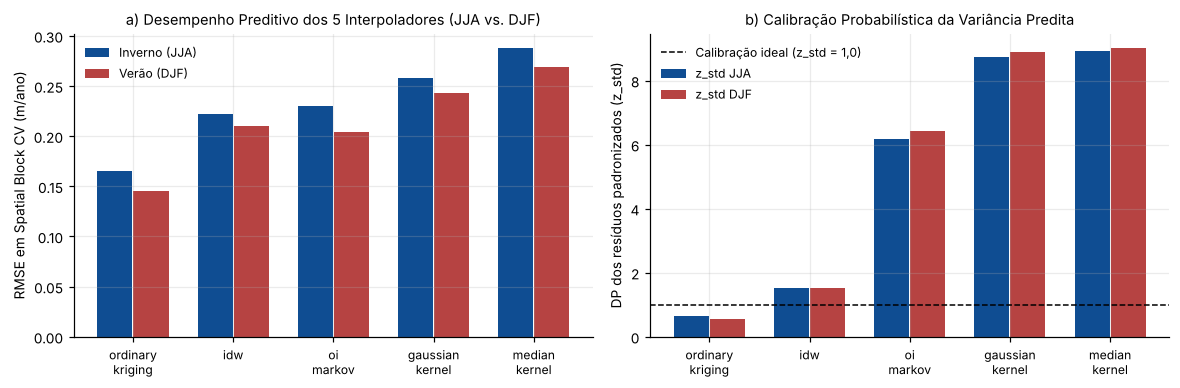

In [8]:
jja_cv = pd.read_csv(DATA_DIR / "jja_interp_cv_metrics.csv")
djf_cv = pd.read_csv(DATA_DIR / "djf_interp_cv_metrics.csv")
# Alinha DJF à ordem dos métodos de JJA (os CSVs vêm ordenados por RMSE, que difere entre as estações)
djf_cv = djf_cv.set_index("method").loc[jja_cv["method"]].reset_index()

fig, ax = plt.subplots(1, 2, figsize=(10.8, 3.6))
x_m = np.arange(len(jja_cv))
ax[0].bar(x_m - 0.18, jja_cv["rmse"], width=0.35, color="#0F4D92", label="Inverno (JJA)")
ax[0].bar(x_m + 0.18, djf_cv["rmse"], width=0.35, color="#B64342", label="Verão (DJF)")
ax[0].set_xticks(x_m)
ax[0].set_xticklabels([m.replace("_", "\n") for m in jja_cv["method"]], fontsize=8)
ax[0].set_ylabel("RMSE em Spatial Block CV (m/ano)")
ax[0].set_title("a) Desempenho Preditivo dos 5 Interpoladores (JJA vs. DJF)")
ax[0].legend(frameon=False, fontsize=8)

ax[1].bar(x_m - 0.18, jja_cv["cal_zstd"], width=0.35, color="#0F4D92", label="z_std JJA")
ax[1].bar(x_m + 0.18, djf_cv["cal_zstd"], width=0.35, color="#B64342", label="z_std DJF")
ax[1].axhline(1.0, color="k", ls="--", lw=1.0, label="Calibração ideal (z_std = 1,0)")
ax[1].set_xticks(x_m)
ax[1].set_xticklabels([m.replace("_", "\n") for m in jja_cv["method"]], fontsize=8)
ax[1].set_ylabel("DP dos resíduos padronizados (z_std)")
ax[1].set_title("b) Calibração Probabilística da Variância Predita")
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout()

jja_cv.merge(djf_cv, on="method", suffixes=("_JJA", "_DJF")).set_index("method").round(4)

**Leitura da figura.**
- **(a)** A krigagem ordinária tem o menor RMSE nas duas estações (≈ 0,15–0,17 m/ano), 25–30% melhor que a segunda colocada (IDW em JJA, OI/Markov em DJF). O vencedor é o mesmo nas duas estações processadas de forma independente, o que indica uma escolha robusta.
- **(b)** A krigagem é a única com $z_{\text{std}} < 1$ (0,56–0,64): sua variância de predição é **conservadora**, maior que o erro real. A interpolação ótima (OI/Markov) e os kernels têm $z_{\text{std}}$ entre 6 e 9: prometem incertezas 6–9× menores que o erro real e não poderiam ser propagadas para o balanço de massa.
- A cobertura de $1\sigma$ da krigagem (93%, acima dos 68% nominais) confirma a leitura de (b). O pipeline adota a krigagem e usa o alcance $L$ dos seus resíduos fora da amostra para a incerteza regional (Caderno 04).

### 4.1 Extensão: interpolação espaço-tempo (cubos)

**Fundamentação.** A krigagem acima interpola a **taxa** dh/dt: um mapa só. A interpolação espaço-tempo (`thwaites.interp.spacetime`, inspirada no `interpgaus3d.py` do captoolkit) estima a anomalia de altura em qualquer ponto **e data**, ponderando cada observação pela distância no espaço e no tempo:
$$w_i = e^{-d_i^2/2\alpha_d^2}\; e^{-\Delta t_i^2/2\alpha_t^2}$$
O resultado é um **cubo** (tempo × y × x): um mapa por data. Deve ser aplicado a resíduos (`h_res = h_corr − REMA`), nunca à altura bruta.

**Aplicação.** Região sintética de 30 × 30 km com afinamento de −0,4 m/ano, mais forte perto da borda sul, e um **degrau de −2 m em 2024,17** numa subárea (imitando a ruptura da Fig. 4 do pôster). Montamos o cubo com duas janelas de tempo, $\alpha_t$ = 3 e 9 meses:

,α_t = 3 meses,α_t = 9 meses
Pixels do cubo com valor (%),100.00,100.00
Erro RMS vs. verdade (m),0.16,0.24
Degrau visto em ±3 meses (verdade: −2 m),-1.38,-0.43


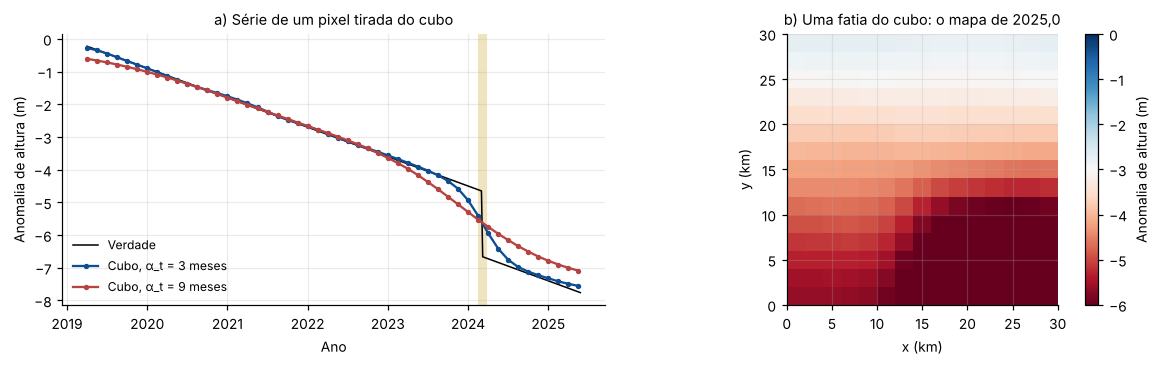

In [9]:
from thwaites.interp.spacetime import build_spacetime_cube

rng = np.random.default_rng(42)
n = 12_000
px, py = rng.uniform(0, 30e3, n), rng.uniform(0, 30e3, n)
pt = rng.uniform(2019.0, 2025.5, n)
def verdade(x, y, t):
    taxa = -0.4 - 0.6 * (1 - y / 30e3)                         # afina mais ao sul
    degrau = np.where((x > 15e3) & (y < 12e3) & (t >= 2024.17), -2.0, 0.0)
    return taxa * (t - 2019.0) + degrau
pv = verdade(px, py, pt) + rng.normal(0, 0.3, n)

xg = yg = np.arange(1e3, 30e3, 2e3)
tg = np.arange(2019.25, 2025.5, 0.125)
cubos = {a_t: build_spacetime_cube(px, py, pt, pv, xg, yg, tg, alpha_d_m=3e3, alpha_t_yr=a_t)
         for a_t in (0.25, 0.75)}

ix, iy = np.argmin(abs(xg - 23e3)), np.argmin(abs(yg - 5e3))       # pixel dentro da área do degrau
fig, ax = plt.subplots(1, 2, figsize=(10.8, 3.4))
tt = np.linspace(2019.25, 2025.4, 400)
ax[0].plot(tt, verdade(23e3, 5e3, tt), "k-", lw=1, label="Verdade")
for a_t, cor in [(0.25, "#0F4D92"), (0.75, "#B64342")]:
    ax[0].plot(tg, cubos[a_t]["pred"][:, iy, ix], "o-", ms=2.5, color=cor, label=f"Cubo, α_t = {a_t*12:.0f} meses")
ax[0].axvline(2024.17, color="#E9D9A6", lw=6, alpha=0.7, zorder=0)
ax[0].set_xlabel("Ano"); ax[0].set_ylabel("Anomalia de altura (m)")
ax[0].set_title("a) Série de um pixel tirada do cubo"); ax[0].legend(frameon=False, fontsize=8)
k = np.argmin(abs(tg - 2025.0))
im = ax[1].imshow(cubos[0.25]["pred"][k], origin="lower", extent=[0, 30, 0, 30], cmap="RdBu", vmin=-6, vmax=0)
plt.colorbar(im, ax=ax[1], label="Anomalia de altura (m)")
ax[1].set_title("b) Uma fatia do cubo: o mapa de 2025,0"); ax[1].set_xlabel("x (km)"); ax[1].set_ylabel("y (km)")
plt.tight_layout()

def degrau_visto(serie, janela=0.25):
    """Degrau medido no cubo: resíduo 3 meses depois menos 3 meses antes de 2024,17 (verdade: −2 m)."""
    taxa_pix = -0.4 - 0.6 * (1 - yg[iy] / 30e3)
    res = serie - taxa_pix * (tg - 2019.0)
    return np.interp(2024.17 + janela, tg, res) - np.interp(2024.17 - janela, tg, res)
Xg, Yg = np.meshgrid(xg, yg)
cubo_verdade = verdade(Xg[None], Yg[None], tg[:, None, None])
pd.DataFrame({f"α_t = {a_t*12:.0f} meses": {
    "Pixels do cubo com valor (%)": 100 * np.isfinite(c["pred"]).mean(),
    "Erro RMS vs. verdade (m)": float(np.sqrt(np.nanmean((c["pred"] - cubo_verdade) ** 2))),
    "Degrau visto em ±3 meses (verdade: −2 m)": degrau_visto(c["pred"][:, iy, ix]),
} for a_t, c in cubos.items()}).round(2)

**Leitura do resultado.**
- **(a)** O cubo reconstrói a série de qualquer pixel, inclusive onde o satélite não passou naquela data. Mas o degrau, que na verdade é instantâneo, aparece **espalhado** por vários meses, tanto mais quanto maior for $\alpha_t$. Na tabela: nos 6 meses em volta do evento, a janela de 3 meses mostra só ~1,4 m dos 2 m do degrau, e a de 9 meses, só ~0,4 m. Nas pontas da série (2019 e 2025) a janela só tem dados de um lado, e o cubo se afasta da verdade, mais ainda com janela longa.
- **(b)** Cada fatia do cubo é um mapa completo daquela data: o afinamento mais forte ao sul e a área do degrau aparecem juntos.
- **A escolha de $\alpha_t$ é um compromisso:** janelas curtas preservam melhor eventos bruscos, mas ficam mais ruidosas e com mais lacunas; janelas longas suavizam e preenchem, mas borram as mudanças rápidas.
- **Uso no projeto:** o cubo é útil para mapas por data, animações e comparação com o ATL15. Para **testar** eventos abruptos, como a ruptura de 2024, o pipeline continua usando séries por temporada e o teste de degrau por ΔBIC (Caderno 00, §2.8), que não suavizam o sinal. Antes de propagar o `rmse` do cubo para massa, ele deve ser calibrado por validação cruzada em blocos, como feito para a krigagem.

---
## 5. Síntese do Caderno

| Etapa | Decisão | Evidência |
|---|---|---|
| Domínio | nós com centro em gelo apoiado, ≥ 5 km da linha de aterramento, ≥ 50% de fração apoiada | 1.464 nós removidos; skewness $-2{,}47 \to -2{,}01$ (§0) |
| Estimador | `fitsec`: quadrática local + tendência + rejeição MAD | recupera dh/dt sintético; sem termos espaciais erra > 10× (§1) |
| Verificação | cruzamentos e medianas em painel balanceado concordam | diferença de cm/ano e +0,04 m (§0) |
| Aceleração | reportada só em 0,43% dos nós | ΔAICc engana sob AR(1); bootstrap por ano rejeita (§2) |
| Janela sazonal | JJA mantida, viés tratado como incerteza | aliasing ~2%; JJA − DJF ~6%; ATL15 JJA/anual = 0,86 (§3) |
| Interpolação | krigagem ordinária | menor RMSE e única com $z_{\text{std}} < 1$ (§4) |

**Scripts do pipeline:** `pipelines/gelo_apoiado/run_mask.py`, `run_grounded_mask.py`, `run_dhdt.py`, `run_acceleration.py`, `run_aliasing.py`, `run_xover.py`, `run_interpolation.py`, `run_atl15_validation.py`, `pipelines/figures/run_perfil_bruto.py`.

**Próximo caderno:** o Caderno 04 converte o campo de dh/dt em perda de massa e propaga a incerteza espacialmente correlacionada.